## Hyperparameters and Parameters

In [15]:
import pandas as pd

# Load data
credit = pd.read_csv('data/credit-card-full.csv')

credit_sample = credit.sample(n=2000, random_state=42)
credit_sample.head()

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
2308,2309,30000,1,2,2,25,0,0,0,0,...,12580,13716,14828,1500,2000,1500,1500,1500,2000,0
22404,22405,150000,2,1,2,26,0,0,0,0,...,101581,77741,77264,4486,4235,3161,2647,2669,2669,0
23397,23398,70000,2,3,1,32,0,0,0,0,...,69753,70111,70212,2431,3112,3000,2438,2500,2554,0
25058,25059,130000,1,3,2,49,0,0,0,0,...,16898,11236,6944,1610,1808,7014,27,7011,4408,0
2664,2665,50000,2,2,2,36,0,0,0,0,...,19574,20295,19439,2000,1500,1000,1800,0,1000,1


In [16]:
from sklearn.model_selection import train_test_split
X = credit_sample.drop('default payment next month', axis=1)
y = credit_sample['default payment next month']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [17]:
from sklearn.linear_model import LogisticRegression

log_reg_clf = LogisticRegression(max_iter=1000)

log_reg_clf.fit(X_train, y_train)

/home/omer-yaslitas/projects/datacamp-ml-track/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

In [18]:
# Create a list of original variable names from the training DataFrame
original_variables = X_train.columns

# Extract the coefficients of the logistic regression estimator
model_coefficients = log_reg_clf.coef_[0]

# Create a dataframe of the variables and coefficients & print it out
coefficient_df = pd.DataFrame({"Variable" : original_variables, "Coefficient": model_coefficients})
print(coefficient_df)

# Print out the top 3 positive variables
top_three_df = coefficient_df.sort_values(by="Coefficient", axis=0, ascending=False)[0:3]
print(top_three_df)

     Variable   Coefficient
0          ID -1.161103e-05
1   LIMIT_BAL  3.309245e-07
2         SEX -3.369016e-02
3   EDUCATION -3.006968e-02
4    MARRIAGE -3.195244e-02
5         AGE -1.193303e-02
6       PAY_0  1.724387e-01
7       PAY_2  9.520419e-02
8       PAY_3  8.845432e-02
9       PAY_4  9.393344e-02
10      PAY_5  8.810838e-02
11      PAY_6  8.093038e-02
12  BILL_AMT1 -3.945208e-06
13  BILL_AMT2 -6.341701e-06
14  BILL_AMT3  6.358849e-06
15  BILL_AMT4  1.303906e-05
16  BILL_AMT5 -1.484573e-06
17  BILL_AMT6 -3.943097e-06
18   PAY_AMT1 -4.198271e-05
19   PAY_AMT2 -6.969565e-05
20   PAY_AMT3 -3.537628e-05
21   PAY_AMT4 -2.322883e-05
22   PAY_AMT5 -2.665708e-05
23   PAY_AMT6  1.200077e-06
  Variable  Coefficient
6    PAY_0     0.172439
7    PAY_2     0.095204
9    PAY_4     0.093933


In [19]:
from sklearn.ensemble import RandomForestClassifier

rf_clf = RandomForestClassifier(max_depth=2, random_state=42)
rf_clf.fit(X_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",2
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap:

In [ ]:
import io
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
from sklearn.tree import plot_tree

plt.figure(figsize=(10, 6), dpi=100)
plot_tree(
    rf_clf.estimators_[6],
    feature_names=list(X_train.columns),
    filled=True,
    rounded=True,
)
plt.axis("off")

buf = io.BytesIO()
plt.savefig(buf, format="png", bbox_inches="tight", pad_inches=0.1)
buf.seek(0)
plt.close()

img = Image.open(buf)
tree_viz_image = np.array(img)

print(tree_viz_image.shape)

(482, 795, 4)


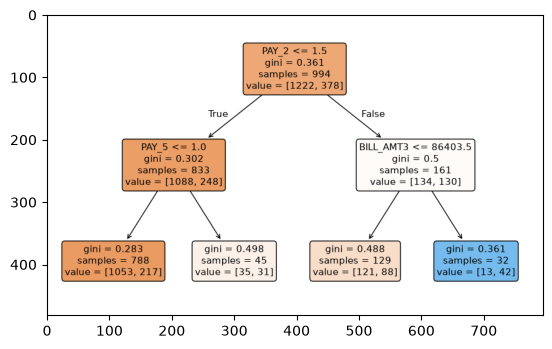

This node split on feature PAY_2, at a value of 1.5


In [21]:
# Extract the 7th (index 6) tree from the random forest
chosen_tree = rf_clf.estimators_[6]

# Visualize the graph using the provided image
imgplot = plt.imshow(tree_viz_image)
plt.show()

# Extract the parameters and level of the top (index 0) node
split_column = chosen_tree.tree_.feature[0]
split_column_name = X_train.columns[split_column]
split_value = chosen_tree.tree_.threshold[0]

# Print out the feature and level
print("This node split on feature {}, at a value of {}".format(split_column_name, split_value))

In [22]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

# Build a knn estimator for each value of n_neighbours
knn_5 = KNeighborsClassifier(n_neighbors=5)
knn_10 = KNeighborsClassifier(n_neighbors=10)
knn_20 = KNeighborsClassifier(n_neighbors=20)

# Fit each to the training data & produce predictions
knn_5_predictions = knn_5.fit(X_train, y_train).predict(X_test)
knn_10_predictions = knn_10.fit(X_train, y_train).predict(X_test)
knn_20_predictions = knn_20.fit(X_train, y_train).predict(X_test)

# Get an accuracy score for each of the models
knn_5_accuracy = accuracy_score(y_test, knn_5_predictions)
knn_10_accuracy = accuracy_score(y_test, knn_10_predictions)
knn_20_accuracy = accuracy_score(y_test, knn_20_predictions)
print("The accuracy of 5, 10, 20 neighbours was {}, {}, {}".format(knn_5_accuracy, knn_10_accuracy, knn_20_accuracy))

The accuracy of 5, 10, 20 neighbours was 0.725, 0.76, 0.7825


### Automating Hyperparameter Tuning

In [23]:
from sklearn.ensemble import GradientBoostingClassifier
# Set the learning rates & results storage
learning_rates = [0.001, 0.01, 0.05, 0.1, 0.2, 0.5]
results_list = []

# Create the for loop to evaluate model predictions for each learning rate
for learning_rate in learning_rates:
    model = GradientBoostingClassifier(learning_rate=learning_rate, random_state=42)
    predictions = model.fit(X_train, y_train).predict(X_test)
    # Save the learning rate and accuracy score
    results_list.append([learning_rate, accuracy_score(y_test, predictions)])

# Gather everything into a DataFrame
results_df = pd.DataFrame(results_list, columns=['learning_rate', 'accuracy'])
print(results_df)

   learning_rate  accuracy
0          0.001    0.7825
1          0.010    0.8025
2          0.050    0.8075
3          0.100    0.8000
4          0.200    0.7825
5          0.500    0.7775


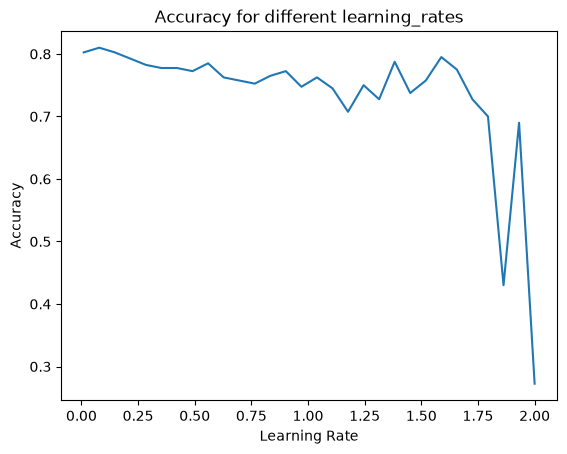

In [28]:
import numpy as np
import matplotlib.pyplot as plt

# Set the learning rates & accuracies list
learn_rates = np.linspace(0.01, 2, num=30)
accuracies = []

# Create the for loop
for learn_rate in learn_rates:
  	# Create the model, predictions & save the accuracies as before
    model = GradientBoostingClassifier(learning_rate=learn_rate)
    predictions = model.fit(X_train, y_train).predict(X_test)
    accuracies.append(accuracy_score(y_test, predictions))

# Plot results    
plt.plot(learn_rates, accuracies)
plt.gca().set(xlabel='Learning Rate', ylabel='Accuracy', title='Accuracy for different learning_rates')
plt.show()

## Grid search

In [2]:
import pandas as pd

# Load data
credit = pd.read_csv('data/credit-card-full.csv')

credit_sample = credit.sample(n=2000, random_state=42)
credit_sample.head()

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
2308,2309,30000,1,2,2,25,0,0,0,0,...,12580,13716,14828,1500,2000,1500,1500,1500,2000,0
22404,22405,150000,2,1,2,26,0,0,0,0,...,101581,77741,77264,4486,4235,3161,2647,2669,2669,0
23397,23398,70000,2,3,1,32,0,0,0,0,...,69753,70111,70212,2431,3112,3000,2438,2500,2554,0
25058,25059,130000,1,3,2,49,0,0,0,0,...,16898,11236,6944,1610,1808,7014,27,7011,4408,0
2664,2665,50000,2,2,2,36,0,0,0,0,...,19574,20295,19439,2000,1500,1000,1800,0,1000,1


In [3]:
from sklearn.model_selection import train_test_split

X = credit_sample.drop('default payment next month', axis=1)
y = credit_sample['default payment next month']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [7]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score

# Create the function
def gbm_grid_search(learning_rate, max_depth):

	# Create the model
    model = GradientBoostingClassifier(learning_rate=learning_rate, max_depth=max_depth)
    
    # Use the model to make predictions
    predictions = model.fit(X_train, y_train).predict(X_test)
    
    # Return the hyperparameters and score
    return([learning_rate, max_depth, accuracy_score(y_test, predictions)])

In [8]:
# Create the relevant lists
results_list = []
learn_rate_list = [0.01, 0.1, 0.5]
max_depth_list = [2, 4, 6]

# Create the for loop
for learn_rate in learn_rate_list:
    for max_depth in max_depth_list:
        results_list.append(gbm_grid_search(learn_rate, max_depth))

# Print the results
print(results_list)   

[[0.01, 2, 0.8025], [0.01, 4, 0.8025], [0.01, 6, 0.79], [0.1, 2, 0.8], [0.1, 4, 0.795], [0.1, 6, 0.795], [0.5, 2, 0.79], [0.5, 4, 0.7775], [0.5, 6, 0.795]]


In [9]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score

# Create the function
def gbm_grid_search_extended(learning_rate, max_depth, subsample):

	# Create the model
    model = GradientBoostingClassifier(learning_rate=learning_rate, max_depth=max_depth, subsample=subsample)
    
    # Use the model to make predictions
    predictions = model.fit(X_train, y_train).predict(X_test)
    
    # Return the hyperparameters and score
    return([learning_rate, max_depth, accuracy_score(y_test, predictions)])

In [10]:
results_list = []
learn_rate_list = [0.01, 0.1, 0.5]
max_depth_list = [2,4,6]

# Create the new list to test
subsample_list = [0.4, 0.6]

for learn_rate in learn_rate_list:
    for max_depth in max_depth_list:
    
        # Extend the for loop
        for subsample in subsample_list:
        
            # Extend the results to include the new hyperparameter
            results_list.append(gbm_grid_search_extended(learn_rate, max_depth, subsample))
            
# Print results
print(results_list)            

[[0.01, 2, 0.795], [0.01, 2, 0.7975], [0.01, 4, 0.795], [0.01, 4, 0.795], [0.01, 6, 0.8], [0.01, 6, 0.7975], [0.1, 2, 0.8075], [0.1, 2, 0.8075], [0.1, 4, 0.8025], [0.1, 4, 0.81], [0.1, 6, 0.7875], [0.1, 6, 0.805], [0.5, 2, 0.7575], [0.5, 2, 0.77], [0.5, 4, 0.765], [0.5, 4, 0.78], [0.5, 6, 0.75], [0.5, 6, 0.7925]]


In [17]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier

# Create a Random Forest Classifier with specified criterion
rf_class = RandomForestClassifier(criterion='entropy')

# Create the parameter grid
param_grid = {'max_depth': [2, 4, 8, 15], 'max_features': [None, 'sqrt']} 

# Create a GridSearchCV object
grid_rf_class = GridSearchCV(
    estimator=rf_class,
    param_grid=param_grid,
    scoring='roc_auc',
    n_jobs=4,
    cv=5,
    refit=True, return_train_score=True)
print(grid_rf_class)

GridSearchCV(cv=5, estimator=RandomForestClassifier(criterion='entropy'),
             n_jobs=4,
             param_grid={'max_depth': [2, 4, 8, 15],
                         'max_features': [None, 'sqrt']},
             return_train_score=True, scoring='roc_auc')


### Exploring the grid search results

In [18]:
grid_rf_class.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestC...ion='entropy')
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': [2, 4, ...], 'max_features': [None, 'sqrt']}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'roc_auc'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",4
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"return_train_score return_train_score: bool, default=FalseIf ``False``, the ``cv_results_`` attribute will not include trainingscores.Computing training scores is used to get insights on how differentparameter settings impact the overfitting/underfitting trade-off.However computing the scores on the training set can be computationallyexpensive and is not strictly required to select the parameters thatyield the best generalization performance... versionadded:: 0.19.. versionchanged:: 0.21 Default value was changed from ``True`` to ``False``",True
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscor

In [20]:
# Read the cv_results property into a dataframe & print it out
cv_results_df = pd.DataFrame(grid_rf_class.cv_results_)
print(cv_results_df, end="\n\n")

# Extract and print the column with a dictionary of hyperparameters used
column = cv_results_df.loc[:, ['params']]
print(column, end="\n\n")

# Extract and print the row that had the best mean test score
best_row = cv_results_df[cv_results_df['mean_test_score'] == cv_results_df['mean_test_score'].max() ]
print(best_row)

   mean_fit_time  std_fit_time  mean_score_time  std_score_time  \
0       0.290865      0.012805         0.006330        0.000295   
1       0.119957      0.001936         0.006230        0.000173   
2       0.480049      0.008390         0.007135        0.000326   
3       0.159608      0.013785         0.007214        0.000565   
4       0.734729      0.015468         0.007481        0.000414   
5       0.205856      0.008655         0.006978        0.000113   
6       0.865657      0.025896         0.007725        0.000158   
7       0.233349      0.003786         0.007966        0.000296   

   param_max_depth param_max_features  \
0                2                NaN   
1                2               sqrt   
2                4                NaN   
3                4               sqrt   
4                8                NaN   
5                8               sqrt   
6               15                NaN   
7               15               sqrt   

                          

In [24]:
# Print out the ROC_AUC score from the best-performing square
best_score = grid_rf_class.best_score_
print(best_score)

# Create a variable from the row related to the best-performing square
cv_results_df = pd.DataFrame(grid_rf_class.cv_results_)
best_row = cv_results_df.loc[[grid_rf_class.best_index_]]
print(best_row)

# Get the max_depth parameter from the best-performing square and print
best_max_depth = grid_rf_class.best_params_["max_depth"]
print(best_max_depth)

0.7594549338876379
   mean_fit_time  std_fit_time  mean_score_time  std_score_time  \
3       0.159608      0.013785         0.007214        0.000565   

   param_max_depth param_max_features  \
3                4               sqrt   

                                     params  split0_test_score  \
3  {'max_depth': 4, 'max_features': 'sqrt'}           0.786073   

   split1_test_score  split2_test_score  ...  mean_test_score  std_test_score  \
3           0.776257           0.731566  ...         0.759455        0.021483   

   rank_test_score  split0_train_score  split1_train_score  \
3                1            0.828557            0.833775   

   split2_train_score  split3_train_score  split4_train_score  \
3             0.83633            0.834317            0.834362   

   mean_train_score  std_train_score  
3          0.833468         0.002605  

[1 rows x 22 columns]
4


In [25]:
# See what type of object the best_estimator_ property is
from sklearn.metrics import confusion_matrix, roc_auc_score


print(type(grid_rf_class.best_estimator_))

# Create an array of predictions directly using the best_estimator_ property
predictions = grid_rf_class.best_estimator_.predict(X_test)

# Take a look to confirm it worked, this should be an array of 1's and 0's
print(predictions[0:5])

# Now create a confusion matrix 
print("Confusion Matrix \n", confusion_matrix(y_test, predictions))

# Get the ROC-AUC score
predictions_proba = grid_rf_class.best_estimator_.predict_proba(X_test)[:,1]
print("ROC-AUC Score \n", roc_auc_score(y_test, predictions_proba))

<class 'sklearn.ensemble._forest.RandomForestClassifier'>
[0 1 0 1 0]
Confusion Matrix 
 [[307   6]
 [ 72  15]]
ROC-AUC Score 
 0.753369321728912


## Random Search

In [27]:
import numpy as np
from itertools import product

# Create a list of values for the learning_rate hyperparameter
learn_rate_list = list(np.linspace(0.01, 1.5, 200))

# Create a list of values for the min_samples_leaf hyperparameter
min_samples_list = list(range(10, 41))

# Combination list
combinations_list = [list(x) for x in product(learn_rate_list, min_samples_list)]

# Sample hyperparameter combinations for a random search.
random_combinations_index = np.random.choice(range(0, len(combinations_list)), size=250, replace=False)
combinations_random_chosen = [combinations_list[x] for x in random_combinations_index]

# Print the result
print(combinations_random_chosen)

[[np.float64(0.2720603015075377), 33], [np.float64(0.5790452261306532), 39], [np.float64(0.8111557788944723), 32], [np.float64(1.0058291457286432), 36], [np.float64(0.17472361809045225), 19], [np.float64(0.024974874371859294), 26], [np.float64(0.9234673366834171), 12], [np.float64(1.222964824120603), 37], [np.float64(0.4442713567839196), 32], [np.float64(1.1855276381909547), 19], [np.float64(0.1822110552763819), 17], [np.float64(1.0208040201005024), 22], [np.float64(0.9609045226130652), 38], [np.float64(1.178040201005025), 21], [np.float64(0.5865326633165829), 30], [np.float64(0.9234673366834171), 20], [np.float64(0.06989949748743718), 35], [np.float64(0.43678391959798996), 10], [np.float64(1.07321608040201), 20], [np.float64(1.3652261306532663), 13], [np.float64(0.11482412060301507), 18], [np.float64(1.2978391959798994), 26], [np.float64(1.0807035175879396), 11], [np.float64(1.178040201005025), 32], [np.float64(0.039949748743718594), 12], [np.float64(1.4625628140703517), 39], [np.floa

In [30]:
# Create lists for criterion and max_features
import random


criterion_list = ['gini', 'entropy']
max_feature_list = ['auto', 'sqrt', 'log2', None]

# Create a list of values for the max_depth hyperparameter
max_depth_list = list(range(3,56))

# Combination list
combinations_list = [list(x) for x in product(criterion_list, max_feature_list, max_depth_list)]

# Sample hyperparameter combinations for a random search
combinations_random_chosen = random.sample(combinations_list, 150)

# Print the result
print(combinations_random_chosen)

[['gini', 'sqrt', 15], ['gini', 'sqrt', 35], ['gini', 'sqrt', 34], ['gini', 'auto', 44], ['gini', 'log2', 54], ['gini', 'auto', 49], ['gini', 'log2', 8], ['entropy', 'auto', 41], ['gini', None, 10], ['gini', None, 17], ['entropy', 'log2', 52], ['entropy', None, 14], ['gini', 'sqrt', 46], ['entropy', None, 22], ['gini', 'log2', 33], ['entropy', 'log2', 54], ['gini', 'auto', 9], ['entropy', 'sqrt', 9], ['entropy', None, 25], ['entropy', 'auto', 7], ['gini', 'log2', 52], ['gini', None, 4], ['gini', 'auto', 37], ['entropy', 'log2', 43], ['entropy', 'log2', 3], ['gini', 'auto', 29], ['gini', 'log2', 7], ['gini', 'sqrt', 44], ['gini', 'sqrt', 29], ['entropy', 'auto', 3], ['gini', 'auto', 11], ['entropy', None, 50], ['gini', 'auto', 3], ['gini', 'auto', 23], ['entropy', None, 52], ['entropy', None, 49], ['gini', None, 29], ['gini', 'log2', 27], ['entropy', None, 7], ['entropy', 'log2', 10], ['gini', 'log2', 34], ['entropy', 'log2', 55], ['entropy', 'sqrt', 33], ['gini', 'log2', 19], ['entropy

In [41]:
# From DataCamp
import numpy as np
import matplotlib.pyplot as plt

x_lims = [0.01, 1.5]
y_lims = [10, 29]

x_lims = (min(learn_rate_list), max(learn_rate_list))
y_lims = (min(min_samples_list), max(min_samples_list))

def sample_and_visualize_hyperparameters(n_samples):

  # If asking for all combinations, just return the entire list.
  if n_samples == len(combinations_list):
    combinations_random_chosen = combinations_list
  else:
    combinations_random_chosen = []
    random_combinations_index = np.random.choice(range(0, len(combinations_list)), n_samples, replace=False)
    combinations_random_chosen = [combinations_list[x] for x in random_combinations_index]
    
  # Pull out the X and Y to plot
  rand_y, rand_x = [float(x[0]) for x in combinations_random_chosen], [float(x[1]) for x in combinations_random_chosen]

  # Plot 
  plt.clf() 
  plt.scatter(rand_y, rand_x, c=['blue']*len(combinations_random_chosen))
  plt.gca().set(xlabel='learn_rate', ylabel='min_samples_leaf', title='Random Search Hyperparameters')
  plt.gca().set_xlim(x_lims)
  plt.gca().set_ylim(y_lims)
  plt.show()

In [44]:
# Create a list of values for the learning_rate hyperparameter
learn_rate_list = list(np.linspace(0.01, 1.5, 200))

# Create a list of values for the min_samples_leaf hyperparameter
min_samples_list = list(range(10, 41))

# Combination list
combinations_list = [list(x) for x in product(learn_rate_list, min_samples_list)]

6200


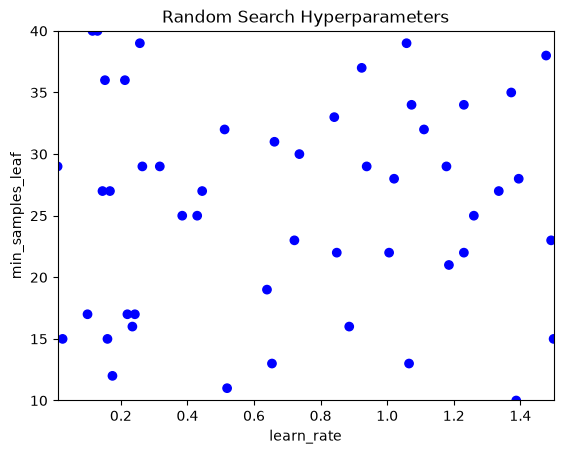

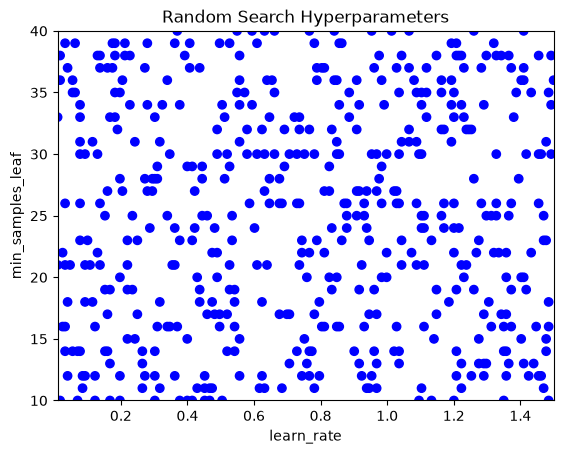

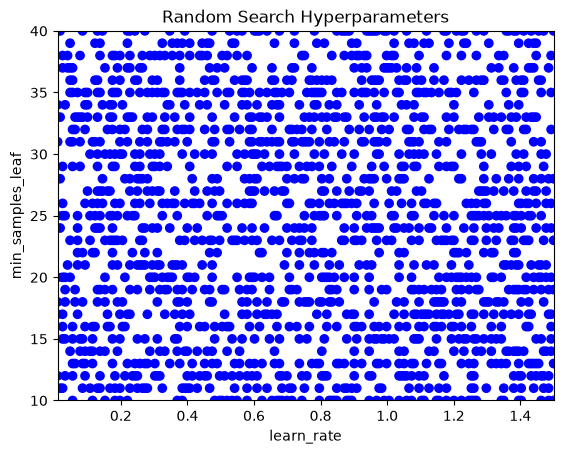

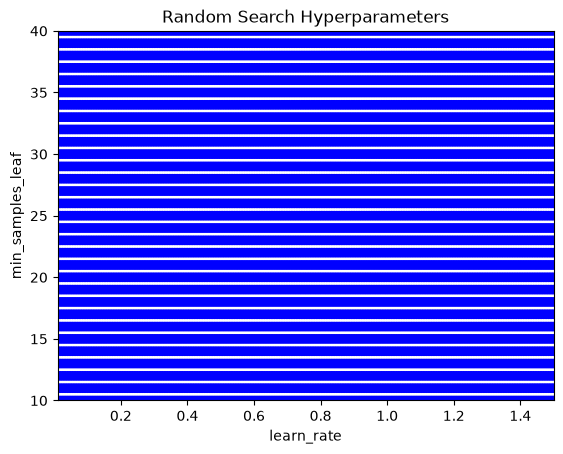

In [46]:
# Confirm how many hyperparameter combinations & print
number_combs = len(combinations_list)
print(number_combs)

# Sample and visualise specified combinations
for x in [50, 500, 1500]:
    sample_and_visualize_hyperparameters(x)
    
# Sample all the hyperparameter combinations & visualise
sample_and_visualize_hyperparameters(number_combs)

In [48]:
# Create the parameter grid
from sklearn.model_selection import RandomizedSearchCV


param_grid = {'learning_rate': np.linspace(0.1,2.0,150), 'min_samples_leaf': list(range(20,65))} 

# Create a random search object
random_GBM_class = RandomizedSearchCV(
    estimator = GradientBoostingClassifier(),
    param_distributions = param_grid,
    n_iter = 10,
    scoring='accuracy', n_jobs=4, cv = 5, refit=True, return_train_score = True)

# Fit to the training data
random_GBM_class.fit(X_train, y_train)

# Print the values used for both hyperparameters
print(random_GBM_class.cv_results_['param_learning_rate'])
print(random_GBM_class.cv_results_['param_min_samples_leaf'])

[0.4825503355704698 0.9798657718120805 0.6355704697986577
 0.3677852348993289 1.4389261744966444 0.6100671140939596
 1.4899328859060403 0.1 0.9288590604026845 1.1711409395973156]
[42 27 53 27 56 44 21 56 47 22]


In [51]:
# Create the parameter grid
param_grid = {'max_depth': list(range(5,26)), 'max_features': ['sqrt' , None]} 

# Create a random search object
random_rf_class = RandomizedSearchCV(
    estimator = RandomForestClassifier(n_estimators=80),
    param_distributions = param_grid, n_iter = 5,
    scoring='roc_auc', n_jobs=4, cv = 3, refit=True, return_train_score = True )

# Fit to the training data
random_rf_class.fit(X_train, y_train)

# Print the values used for both hyperparameters
print(random_rf_class.cv_results_['param_max_depth'])
print(random_rf_class.cv_results_['param_max_features'])

[9 12 22 12 6]
['sqrt' None None 'sqrt' 'sqrt']


In [52]:
# Sample grid coordinates
grid_combinations_chosen = combinations_list[0:300]

# Print result
print(grid_combinations_chosen)

[[np.float64(0.01), 10], [np.float64(0.01), 11], [np.float64(0.01), 12], [np.float64(0.01), 13], [np.float64(0.01), 14], [np.float64(0.01), 15], [np.float64(0.01), 16], [np.float64(0.01), 17], [np.float64(0.01), 18], [np.float64(0.01), 19], [np.float64(0.01), 20], [np.float64(0.01), 21], [np.float64(0.01), 22], [np.float64(0.01), 23], [np.float64(0.01), 24], [np.float64(0.01), 25], [np.float64(0.01), 26], [np.float64(0.01), 27], [np.float64(0.01), 28], [np.float64(0.01), 29], [np.float64(0.01), 30], [np.float64(0.01), 31], [np.float64(0.01), 32], [np.float64(0.01), 33], [np.float64(0.01), 34], [np.float64(0.01), 35], [np.float64(0.01), 36], [np.float64(0.01), 37], [np.float64(0.01), 38], [np.float64(0.01), 39], [np.float64(0.01), 40], [np.float64(0.017487437185929648), 10], [np.float64(0.017487437185929648), 11], [np.float64(0.017487437185929648), 12], [np.float64(0.017487437185929648), 13], [np.float64(0.017487437185929648), 14], [np.float64(0.017487437185929648), 15], [np.float64(0.0

In [53]:
def visualize_search(grid_combinations_chosen, random_combinations_chosen):
  grid_y, grid_x = [x[0] for x in grid_combinations_chosen], [x[1] for x in grid_combinations_chosen]
  rand_y, rand_x = [x[0] for x in random_combinations_chosen], [x[1] for x in random_combinations_chosen]

  # Plot all together
  plt.scatter(grid_y + rand_y, grid_x + rand_x, c=['red']*300 + ['blue']*300)
  plt.gca().set(xlabel='learn_rate', ylabel='min_samples_leaf', title='Grid and Random Search Hyperparameters')
  plt.gca().set_xlim(x_lims)
  plt.gca().set_ylim(y_lims)
  plt.show()

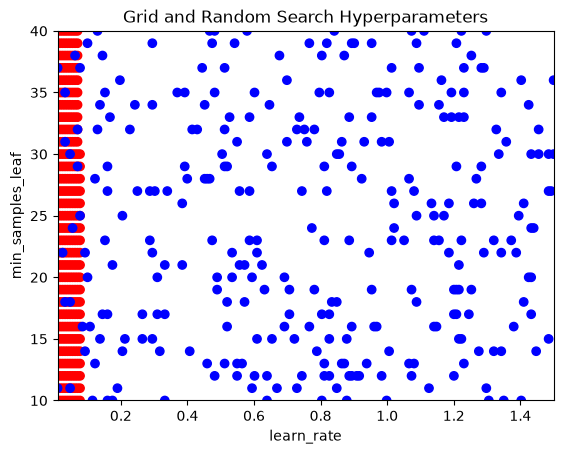

In [55]:
# Create a list of sample indexes
sample_indexes = list(range(0,len(combinations_list)))

# Randomly sample 300 indexes
random_indexes = np.random.choice(sample_indexes, 300, replace=False)

# Use indexes to create random sample
random_combinations_chosen = [combinations_list[index] for index in random_indexes]

# Call the function to produce the visualization
visualize_search(grid_combinations_chosen, random_combinations_chosen)

## Informed Search

In [113]:
import itertools
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import RandomizedSearchCV

max_depth_list = list(np.linspace(5, 60, 30, dtype=int))
min_samples_leaf_list = list(range(2, 20))
learning_rate_list = list(np.linspace(0.01, 2.0, 100))

combinations_list = [
    list(x)
    for x in itertools.product(
        max_depth_list, min_samples_leaf_list, learning_rate_list
    )
]

param_grid = {
    'max_depth': max_depth_list,
    'min_samples_leaf': min_samples_leaf_list,
    'learning_rate': learning_rate_list,
}

random_search = RandomizedSearchCV(
    estimator=GradientBoostingClassifier(random_state=42),
    param_distributions=param_grid,
    n_iter=500,
    scoring='accuracy',
    n_jobs=-1,
    cv=3,
    random_state=42,
)

random_search.fit(X_train, y_train)

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",GradientBoost...ndom_state=42)
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'learning_rate': [np.float64(0.01), np.float64(0.0301010101010101), ...], 'max_depth': [np.int64(5), np.int64(6), ...], 'min_samples_leaf': [2, 3, ...]}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",500
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``RandomizedSea

### Coarse to Fine

In [114]:
results_df = pd.DataFrame(random_search.cv_results_)
results_df.head()

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_min_samples_leaf,param_max_depth,param_learning_rate,params,split0_test_score,split1_test_score,split2_test_score,mean_test_score,std_test_score,rank_test_score
0,3.094287,0.344969,0.008915,0.001903,11,18,0.592929,"{'min_samples_leaf': 11, 'max_depth': 18, 'lea...",0.801498,0.791745,0.797373,0.796872,0.003998,100
1,2.311502,0.211661,0.008105,0.001161,16,37,0.030101,"{'min_samples_leaf': 16, 'max_depth': 37, 'lea...",0.805243,0.803002,0.814259,0.807501,0.004865,7
2,2.094950,0.092384,0.007001,0.000226,18,41,1.417071,"{'min_samples_leaf': 18, 'max_depth': 41, 'lea...",0.779026,0.761726,0.791745,0.777499,0.012303,349
3,2.300249,0.649893,0.006045,0.000939,4,52,1.658283,"{'min_samples_leaf': 4, 'max_depth': 52, 'lear...",0.773408,0.729831,0.795497,0.766246,0.027282,371
4,2.527821,0.151917,0.015955,0.009410,18,54,0.412020,"{'min_samples_leaf': 18, 'max_depth': 54, 'lea...",0.790262,0.780488,0.797373,0.789374,0.006922,234


In [115]:
import pandas as pd

results_df = pd.DataFrame(random_search.cv_results_)
results_df = results_df.rename(columns={'mean_test_score': 'accuracy'})

target_columns = [
    'param_learning_rate',
    'param_min_samples_leaf',
    'accuracy',
    'param_max_depth'
]

# Change mean_test_score to accuracy in the results_df
results_df = results_df.rename(columns={'mean_test_score': 'accuracy'})
results_df['accuracy'] = results_df['accuracy'] * 100


valid_columns = [col for col in target_columns if col in results_df.columns]
results_df = results_df[valid_columns]

print(results_df.head())

   param_learning_rate  param_min_samples_leaf   accuracy  param_max_depth
0             0.592929                      11  79.687211               18
1             0.030101                      16  80.750141               37
2             1.417071                      18  77.749905               41
3             1.658283                       4  76.624552               52
4             0.412020                      18  78.937445               54


In [118]:
def visualize_hyperparameter(name):
  plt.clf()
  plt.scatter(results_df[name],results_df['accuracy'], c=['blue']*500)
  plt.gca().set(xlabel='{}'.format(name), ylabel='accuracy', title='Accuracy for different {}s'.format(name))
  plt.gca().set_ylim([20,100])
  plt.show()

54000
     param_learning_rate  param_min_samples_leaf   accuracy  param_max_depth
398             0.010000                      15  81.561978               35
253             0.010000                      19  81.311939               23
76              0.010000                      19  81.311939               20
402             0.010000                      12  81.187915               23
30              0.010000                      11  80.937758               23
414             0.030101                      13  80.937407                6
1               0.030101                      16  80.750141               37
147             0.010000                      10  80.500219               25
223             0.753737                      12  80.499985               14
486             0.030101                      14  80.499868               39
Index(['param_learning_rate', 'param_min_samples_leaf', 'accuracy',
       'param_max_depth'],
      dtype='str')


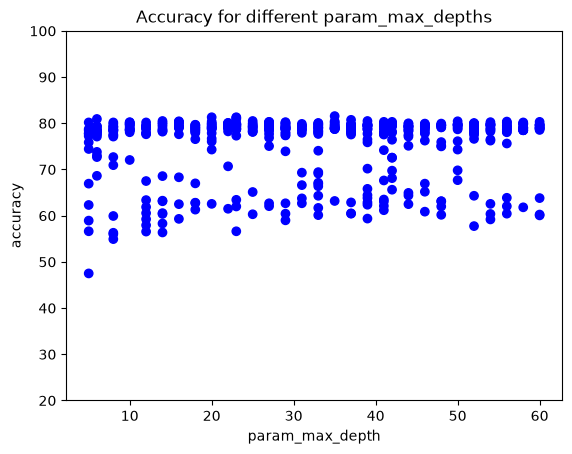

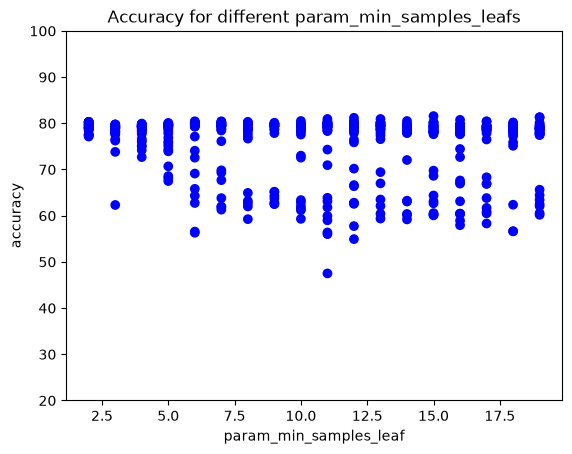

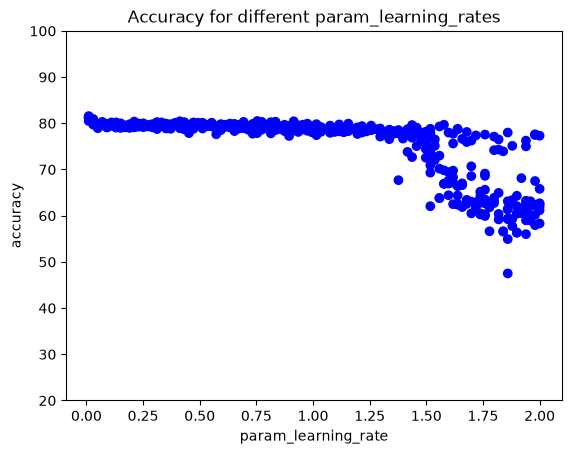

In [119]:
# Confirm the size of the combinations_list
print(len(combinations_list))

# Sort the results_df by accuracy and print the top 10 rows
print(results_df.sort_values(by='accuracy', ascending=False).head(10))

# Confirm which hyperparameters were used in this search
print(results_df.columns)

# Call visualize_hyperparameter() with each hyperparameter in turn
visualize_hyperparameter('param_max_depth')
visualize_hyperparameter('param_min_samples_leaf')
visualize_hyperparameter('param_learning_rate')


In [128]:
def visualize_first():
  for name in results_df.columns[0:2]:
    plt.clf()
    plt.scatter(results_df[name],results_df['accuracy'], c=['blue']*500)
    plt.gca().set(xlabel='{}'.format(name), ylabel='accuracy', title='Accuracy for different {}s'.format(name))
    plt.gca().set_ylim([0,100])
    x_line = 20
    if name == "param_learning_rate":
      x_line = 1
    plt.axvline(x=x_line, color="red", linewidth=4)
    plt.show() 

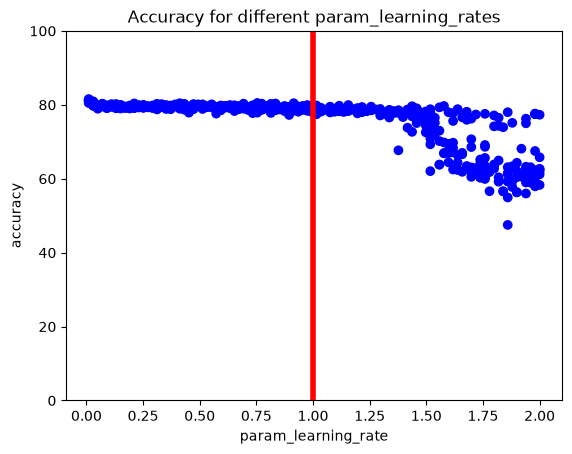

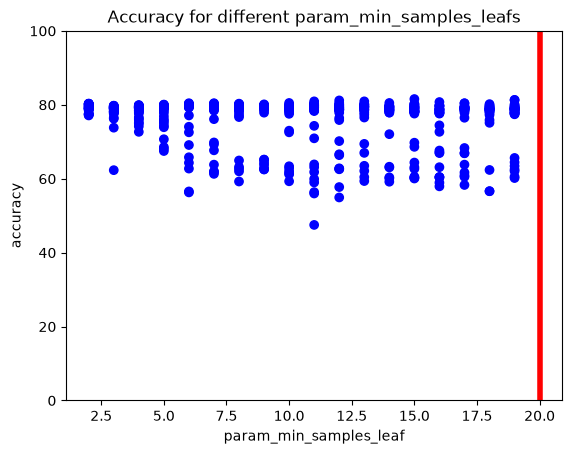

In [129]:
# Use the provided function to visualize the first results
visualize_first()

### Informed Methods: Bayesian Statistics

In [1]:
# Assign probabilities to variables 
p_unhappy = 0.15
p_unhappy_close = 0.35

# Probabiliy someone will close
p_close = 0.07

# Probability unhappy person will close
p_close_unhappy = (p_unhappy_close * p_close) / p_unhappy
print(p_close_unhappy)

0.16333333333333336


In [6]:
import pandas as pd

# Load data
credit = pd.read_csv('data/credit-card-full.csv')

credit_sample = credit.sample(n=2000, random_state=42)
credit_sample.head()
from sklearn.model_selection import train_test_split

X = credit_sample.drop('default payment next month', axis=1)
y = credit_sample['default payment next month']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [7]:
from hyperopt import fmin, hp, tpe
from sklearn.model_selection import cross_val_score
import numpy as np
from sklearn.ensemble import GradientBoostingClassifier

# Set up space dictionary with specified hyperparameters
space = {'max_depth': hp.quniform('max_depth', 2, 10, 2),'learning_rate': hp.uniform('learning_rate', 0.001,0.9)}

# Set up objective function
def objective(params):
    params = {'max_depth': int(params['max_depth']),'learning_rate': params['learning_rate']}
    gbm_clf = GradientBoostingClassifier(n_estimators=100, **params) 
    best_score = cross_val_score(gbm_clf, X_train, y_train, scoring='accuracy', cv=2, n_jobs=4).mean()
    loss = 1 - best_score
    return loss

# Run the algorithm
best = fmin(fn=objective,space=space, max_evals=20, rstate=np.random.default_rng(42), algo=tpe.suggest)
print(best)

100%|██████████| 20/20 [00:09<00:00,  2.15trial/s, best loss: 0.18374999999999997]
{'learning_rate': np.float64(0.038093061276450534), 'max_depth': np.float64(2.0)}


### Informed Methods: Genetic Algorithms

In [3]:
import pandas as pd
import numpy as np

X_train = pd.read_csv('data/X_train.csv', index_col=0)
y_train = np.array([0, 0, 1, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 1, 1, 1, 0, 0, 1, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 1, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 1, 1, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 1, 1, 0, 0, 1, 1, 0, 1, 0, 1, 1, 1, 0, 1, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1, 1, 0, 1, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 1, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 0, 1, 1, 1, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0])

In [4]:
X_test = pd.read_csv('data/X_test.csv', index_col=0)
y_test = np.array([1, 0, 0, 0, 0, 1, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 1, 0, 0, 1, 0, 1, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 1, 0, 0, 1, 1, 1, 0, 0])

In [13]:
from tpot import TPOTClassifier

# Assign the values outlined to the inputs
number_generations = 3
population_size = 4

# Create the tpot classifier
tpot_clf = TPOTClassifier(generations=number_generations, population_size=population_size,
                        verbose=2, random_state=2, cv=2)

# Fit the classifier to the training data
tpot_clf.fit(X_train, y_train)


/home/omer-yaslitas/projects/datacamp-ml-track/.venv/lib/python3.14/site-packages/tpot/tpot_estimator/estimator.py:458: UserWarning: Both generations and max_time_mins are set. TPOT will terminate when the first condition is met.
  warnings.warn("Both generations and max_time_mins are set. TPOT will terminate when the first condition is met.")


Generation:   0%|          | 0/3 [00:00<?, ?it/s]/home/omer-yaslitas/projects/datacamp-ml-track/.venv/lib/python3.14/site-packages/stopit/__init__.py:10: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources
Generation: 100%|██████████| 3/3 [00:27<00:00,  9.01s/it]
/home/omer-yaslitas/projects/datacamp-ml-track/.venv/lib/python3.14/site-packages/sklearn/decomposition/_fastica.py:606: UserWarning: n_components is too large: it will be set to 2
  warnings.warn(
/home/omer-yaslitas/projects/datacamp-ml-track/.venv/lib/python3.14/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


,search_space,<tpot.search_...x766741e18050>
,cv,2
,random_state,2
,scorers,['roc_auc_ovr']
,scorers_weights,[1]
,other_objective_functions,[]
,other_objective_functions_weights,[]
,objective_function_names,None
,bigger_is_better,True
,categorical_features,None
,memory,None


In [14]:
from sklearn.metrics import accuracy_score

y_pred = tpot_clf.predict(X_test)
print(accuracy_score(y_test, y_pred))

0.74
